In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("telco_churn.csv")

print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()
print()
print("Churn counts:")
print(df["Churn"].value_counts())
print()
print("Churn percentages:")
print(df["Churn"].value_counts(normalize=True).round(3) * 100)

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

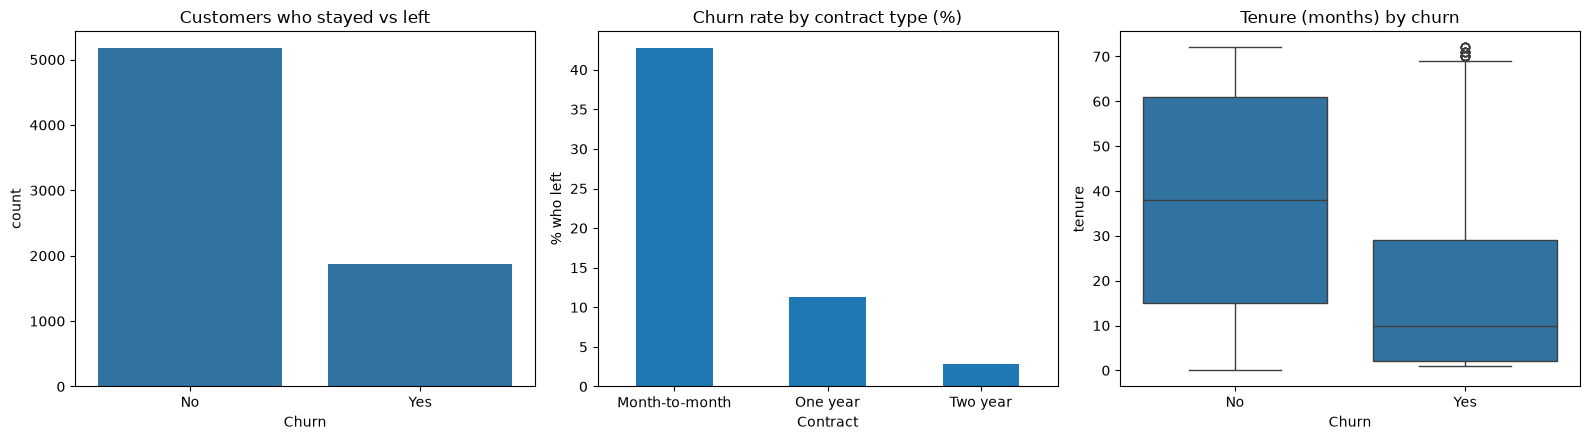

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. How many stayed vs left
sns.countplot(x="Churn", data=df, ax=axes[0])
axes[0].set_title("Customers who stayed vs left")

# 2. Churn rate by contract type
rate = df.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean() * 100)
rate.plot(kind="bar", ax=axes[1])
axes[1].set_title("Churn rate by contract type (%)")
axes[1].set_ylabel("% who left")
axes[1].tick_params(axis="x", rotation=0)

# 3. Tenure for stayers vs leavers
sns.boxplot(x="Churn", y="tenure", data=df, ax=axes[2])
axes[2].set_title("Tenure (months) by churn")

plt.tight_layout()
plt.show()

In [5]:
blank_mask = pd.to_numeric(df["TotalCharges"], errors="coerce").isnull()

print("Rows that are not valid numbers:", blank_mask.sum())
print()
df.loc[blank_mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Rows that are not valid numbers: 11



,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [6]:
df_clean = df.copy()

df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"], errors="coerce").fillna(0)
df_clean = df_clean.drop(columns=["customerID"])

print("TotalCharges dtype:", df_clean["TotalCharges"].dtype)
print("Missing values left:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())
print("Shape:", df_clean.shape)

TotalCharges dtype: float64
Missing values left: 0
Duplicate rows: 22
Shape: (7043, 20)


In [7]:
df_clean["Churn"] = df_clean["Churn"].map({"Yes": 1, "No": 0})
print("Churn counts:", df_clean["Churn"].value_counts().to_dict())
print()

cat_cols = df_clean.select_dtypes(exclude="number").columns.tolist()
print("Text columns to encode:", len(cat_cols))
print()
for col in cat_cols:
    print(f"{col}: {df_clean[col].unique().tolist()}")

Churn counts: {0: 5174, 1: 1869}

Text columns to encode: 15

gender: ['Female', 'Male']
Partner: ['Yes', 'No']
Dependents: ['No', 'Yes']
PhoneService: ['No', 'Yes']
MultipleLines: ['No phone service', 'No', 'Yes']
InternetService: ['DSL', 'Fiber optic', 'No']
OnlineSecurity: ['No', 'Yes', 'No internet service']
OnlineBackup: ['Yes', 'No', 'No internet service']
DeviceProtection: ['No', 'Yes', 'No internet service']
TechSupport: ['No', 'Yes', 'No internet service']
StreamingTV: ['No', 'Yes', 'No internet service']
StreamingMovies: ['No', 'Yes', 'No internet service']
Contract: ['Month-to-month', 'One year', 'Two year']
PaperlessBilling: ['Yes', 'No']
PaymentMethod: ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']


In [8]:
from sklearn.model_selection import train_test_split

features = ["tenure", "MonthlyCharges", "Contract",
            "InternetService", "PaymentMethod", "TechSupport"]

X = pd.get_dummies(df_clean[features], drop_first=True, dtype=int)
y = df_clean["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Columns after encoding:", X.shape[1])
print(list(X.columns))
print()
print("Training rows:", X_train.shape[0])
print("Testing rows: ", X_test.shape[0])
print()
print("Churn rate in train:", round(y_train.mean() * 100, 1), "%")
print("Churn rate in test: ", round(y_test.mean() * 100, 1), "%")

Columns after encoding: 11
['tenure', 'MonthlyCharges', 'Contract_One year', 'Contract_Two year', 'InternetService_Fiber optic', 'InternetService_No', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'TechSupport_No internet service', 'TechSupport_Yes']

Training rows: 5634
Testing rows:  1409

Churn rate in train: 26.5 %
Churn rate in test:  26.5 %


In [9]:
from sklearn.preprocessing import StandardScaler

num_cols = ["tenure", "MonthlyCharges"]

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

print("Scaled training columns (mean ~0, std ~1):")
print(X_train_scaled[num_cols].agg(["mean", "std"]).round(3))
print()
print("Yes/no columns untouched, e.g. Contract_Two year values:",
      sorted(X_train_scaled["Contract_Two year"].unique()))

Scaled training columns (mean ~0, std ~1):
      tenure  MonthlyCharges
mean    -0.0            -0.0
std      1.0             1.0

Yes/no columns untouched, e.g. Contract_Two year values: [np.int64(0), np.int64(1)]


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, confusion_matrix)

log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train_scaled, y_train)

log_pred = log_model.predict(X_test_scaled)

print("Accuracy: ", round(accuracy_score(y_test, log_pred), 3))
print("Precision:", round(precision_score(y_test, log_pred), 3))
print("Recall:   ", round(recall_score(y_test, log_pred), 3))
print()
print("Confusion matrix:")
print(confusion_matrix(y_test, log_pred))

Accuracy:  0.789
Precision: 0.625
Recall:    0.513

Confusion matrix:
[[920 115]
 [182 192]]


In [11]:
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression (plain)": log_model,
    "Logistic Regression (balanced)": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=42),
    "Random Forest (balanced)": RandomForestClassifier(
        n_estimators=200, max_depth=8, min_samples_leaf=10,
        class_weight="balanced", random_state=42, n_jobs=-1),
}

rows = []
for name, model in models.items():
    if name != "Logistic Regression (plain)":
        model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    rows.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, pred), 3),
        "Precision": round(precision_score(y_test, pred), 3),
        "Recall": round(recall_score(y_test, pred), 3),
    })

results = pd.DataFrame(rows)
print(results.to_string(index=False))

                         Model  Accuracy  Precision  Recall
   Logistic Regression (plain)     0.789      0.625   0.513
Logistic Regression (balanced)     0.732      0.497   0.789
      Random Forest (balanced)     0.755      0.526   0.786


In [12]:
final_model = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
final_model.fit(X_train_scaled, y_train)

final_pred = final_model.predict(X_test_scaled)

print("Confusion matrix:")
print(confusion_matrix(y_test, final_pred))
print()
coefs = pd.Series(final_model.coef_[0], index=X_train_scaled.columns)
print(coefs.sort_values().round(2))

Confusion matrix:
[[736 299]
 [ 79 295]]

Contract_Two year                       -1.54
Contract_One year                       -0.80
tenure                                  -0.70
TechSupport_Yes                         -0.41
TechSupport_No internet service         -0.40
InternetService_No                      -0.40
PaymentMethod_Credit card (automatic)   -0.02
PaymentMethod_Mailed check               0.02
MonthlyCharges                           0.26
PaymentMethod_Electronic check           0.51
InternetService_Fiber optic              0.77
dtype: float64


              precision    recall  f1-score   support

      Stayed       0.90      0.71      0.80      1035
        Left       0.50      0.79      0.61       374

    accuracy                           0.73      1409
   macro avg       0.70      0.75      0.70      1409
weighted avg       0.80      0.73      0.75      1409



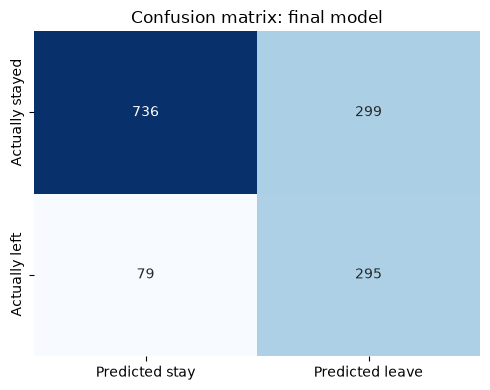

In [13]:
from sklearn.metrics import classification_report

print(classification_report(y_test, final_pred,
                            target_names=["Stayed", "Left"]))

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, final_pred), annot=True, fmt="d",
            cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Predicted stay", "Predicted leave"],
            yticklabels=["Actually stayed", "Actually left"])
ax.set_title("Confusion matrix: final model")
plt.tight_layout()
plt.show()

In [14]:
import joblib, os

joblib.dump(final_model, "churn_model.joblib")
joblib.dump(scaler, "scaler.joblib")
joblib.dump(list(X_train_scaled.columns), "columns.joblib")

for f in ["churn_model.joblib", "scaler.joblib", "columns.joblib"]:
    print(f"{f}: {os.path.getsize(f)/1024:.1f} KB")

churn_model.joblib: 1.5 KB
scaler.joblib: 0.9 KB
columns.joblib: 0.3 KB


In [15]:
model_loaded = joblib.load("churn_model.joblib")
scaler_loaded = joblib.load("scaler.joblib")
columns_loaded = joblib.load("columns.joblib")

def churn_probability(tenure, monthly, contract, internet, payment, tech):
    raw = pd.DataFrame([{
        "tenure": tenure, "MonthlyCharges": monthly, "Contract": contract,
        "InternetService": internet, "PaymentMethod": payment, "TechSupport": tech,
    }])
    row = pd.get_dummies(raw, dtype=int).reindex(columns=columns_loaded, fill_value=0)
    row[["tenure", "MonthlyCharges"]] = scaler_loaded.transform(row[["tenure", "MonthlyCharges"]])
    return model_loaded.predict_proba(row)[0][1]

risky = churn_probability(3, 85.0, "Month-to-month", "Fiber optic", "Electronic check", "No")
safe = churn_probability(60, 25.0, "Two year", "No", "Credit card (automatic)", "No internet service")

print(f"Risky new customer: {risky:.2f}")
print(f"Loyal long-term customer: {safe:.2f}")

Risky new customer: 0.88
Loyal long-term customer: 0.02
